# Part A — Data Understanding, Preprocessing & BiLSTM-CRF

**Goal.** Build a Named Entity Recognition (NER) system that tags tweets with 10 fine-grained entity types
(`person, geo-loc, company, facility, product, musicartist, movie, sportsteam, tvshow, other`) so that Twitter can
surface trends and topics *without relying on user hashtags*.

This notebook covers: data loading & structure analysis, exploratory data analysis, preprocessing,
a TensorFlow tokenizer, Word2Vec-initialised embeddings, and a **BiLSTM + CRF** sequence tagger with
hyper-parameter experiments. Part B (separate notebook) fine-tunes `bert-base-uncased`.

In [1]:
import os, re, json, time, random, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from gensim.models import Word2Vec
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)
random.seed(SEED); np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#1D9BF0", "#0F1419", "#F91880", "#00BA7C", "#FFD400", "#7856FF", "#FF7A00", "#536471", "#8ECDF8", "#C1A3FF"]
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR, OUT_DIR = "../data", "../outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.15.0 | GPUs: []


## 1. Loading the data (CoNLL format)

Each line holds `token<TAB>label`; tweets are separated by a blank line. Labels follow the **BIO** scheme
(`B-` = beginning of an entity, `I-` = inside/continuation, `O` = outside any entity).
The parser below is defensive: it handles Windows line endings, stray whitespace and validates every line.

In [2]:
def read_conll(path):
    """Parse a CoNLL file into parallel lists of token sequences and tag sequences."""
    sentences, tags, toks, labs, bad = [], [], [], [], 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if not line.strip():                      # blank line -> sentence boundary
                if toks:
                    sentences.append(toks); tags.append(labs); toks, labs = [], []
                continue
            parts = line.split("\t") if "\t" in line else line.split()
            if len(parts) < 2:
                bad += 1; continue
            toks.append(parts[0]); labs.append(parts[-1])   # first column = word, last column = label
    if toks:
        sentences.append(toks); tags.append(labs)
    return sentences, tags, bad

train_sents, train_tags, bad_tr = read_conll(f"{DATA_DIR}/wnut 16.txt.conll")
test_sents, test_tags, bad_te = read_conll(f"{DATA_DIR}/wnut 16test.txt.conll")
print(f"Train file : {len(train_sents):>5} tweets | {sum(map(len, train_sents)):>6} tokens | malformed lines: {bad_tr}")
print(f"Test file  : {len(test_sents):>5} tweets | {sum(map(len, test_sents)):>6} tokens | malformed lines: {bad_te}")

Train file :  2394 tweets |  46469 tokens | malformed lines: 0
Test file  :  3850 tweets |  61908 tokens | malformed lines: 0


In [3]:
# Token / label view of two short training tweets (one row per CoNLL line, shown transposed)
short = [i for i, (s, t) in enumerate(zip(train_sents, train_tags)) if len(s) <= 13 and sum(x != "O" for x in t) >= 2][:2]
for i in short:
    display(pd.DataFrame({"token": train_sents[i], "label": train_tags[i]}).T)

,0,1,2,3,4,5,6,7,8,9,10
token,',Breaking,Dawn,',Returns,to,Vancouver,on,January,11th,http://bit.ly/dbDMs8
label,O,B-movie,I-movie,O,O,O,B-geo-loc,O,O,O,O


,0,1,2,3,4,5,6,7,8,9,10,11
token,#SIUC,Whats,the,Plan,For,tonight,??,Whos,Goin,to,the,BLAST
label,O,O,O,O,O,O,O,O,O,O,B-facility,I-facility


In [4]:
def to_frame(sents, tags, split):
    return pd.DataFrame([(split, i, j, w, t) for i, (s, ts) in enumerate(zip(sents, tags))
                         for j, (w, t) in enumerate(zip(s, ts))],
                        columns=["split", "sent_id", "position", "token", "tag"])

df = pd.concat([to_frame(train_sents, train_tags, "train"), to_frame(test_sents, test_tags, "test")], ignore_index=True)
df["entity_type"] = df.tag.str.replace(r"^[BI]-", "", regex=True)
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 108377 entries, 0 to 108376
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   split        108377 non-null  str  
 1   sent_id      108377 non-null  int64
 2   position     108377 non-null  int64
 3   token        108377 non-null  str  
 4   tag          108377 non-null  str  
 5   entity_type  108377 non-null  str  
dtypes: int64(2), str(4)
memory usage: 5.0 MB


,split,sent_id,position,token,tag,entity_type
0,train,0,0,@SammieLynnsMom,O,O
1,train,0,1,@tg10781,O,O
2,train,0,2,they,O,O
3,train,0,3,will,O,O
4,train,0,4,be,O,O


## 2. Data structure analysis & EDA
### 2.1 Label inventory and BIO integrity check

In [5]:
ENTITY_TYPES = sorted({t[2:] for t in df.tag if t != "O"})
LABELS = ["O"] + [f"{p}-{e}" for e in ENTITY_TYPES for p in ("B", "I")]
print(f"{len(ENTITY_TYPES)} entity types -> {len(LABELS)} BIO labels")
print(ENTITY_TYPES)

def bio_violations(tag_seqs):
    """Count I-X tags that are not preceded by B-X or I-X (invalid BIO transitions)."""
    v = 0
    for seq in tag_seqs:
        prev = "O"
        for t in seq:
            if t.startswith("I-") and prev[2:] != t[2:]:
                v += 1
            prev = t
    return v

print("BIO violations  train:", bio_violations(train_tags), "| test:", bio_violations(test_tags))
print("Null/empty tokens:", (df.token.str.strip() == "").sum(), "| duplicated tweets in train:",
      len(train_sents) - len({" ".join(s) for s in train_sents}))

10 entity types -> 21 BIO labels
['company', 'facility', 'geo-loc', 'movie', 'musicartist', 'other', 'person', 'product', 'sportsteam', 'tvshow']
BIO violations  train: 0 | test: 0
Null/empty tokens: 0 | duplicated tweets in train: 99


In [6]:
def extract_entities(tokens, tags):
    """Return list of (entity_type, entity_text, length) spans from a BIO sequence."""
    ents, cur, typ = [], [], None
    for w, t in zip(tokens + [""], tags + ["O"]):     # sentinel "O" flushes the last open entity
        if t.startswith("B-") or t == "O" or (t.startswith("I-") and t[2:] != typ):
            if cur:
                ents.append((typ, " ".join(cur), len(cur)))
            cur, typ = ([w], t[2:]) if t != "O" else ([], None)
        else:
            cur.append(w)
    return ents

ent_rows = [(split, *e) for split, S, T in [("train", train_sents, train_tags), ("test", test_sents, test_tags)]
            for s, t in zip(S, T) for e in extract_entities(s, t)]
ents = pd.DataFrame(ent_rows, columns=["split", "type", "text", "length"])

summary = pd.DataFrame({
    "tweets": [len(train_sents), len(test_sents)],
    "tokens": [sum(map(len, train_sents)), sum(map(len, test_sents))],
    "entities": [(ents.split == "train").sum(), (ents.split == "test").sum()],
    "tweets_with_entity": [sum(any(t != "O" for t in ts) for ts in train_tags),
                           sum(any(t != "O" for t in ts) for ts in test_tags)],
    "pct_O_tokens": [round(100 * np.mean([t == "O" for ts in train_tags for t in ts]), 2),
                     round(100 * np.mean([t == "O" for ts in test_tags for t in ts]), 2)],
}, index=["train", "test"])
summary

,tweets,tokens,entities,tweets_with_entity,pct_O_tokens
train,2394,46469,1496,918,94.70
test,3850,61908,3473,2014,90.38


### 2.2 Entity-type distribution (train vs test)

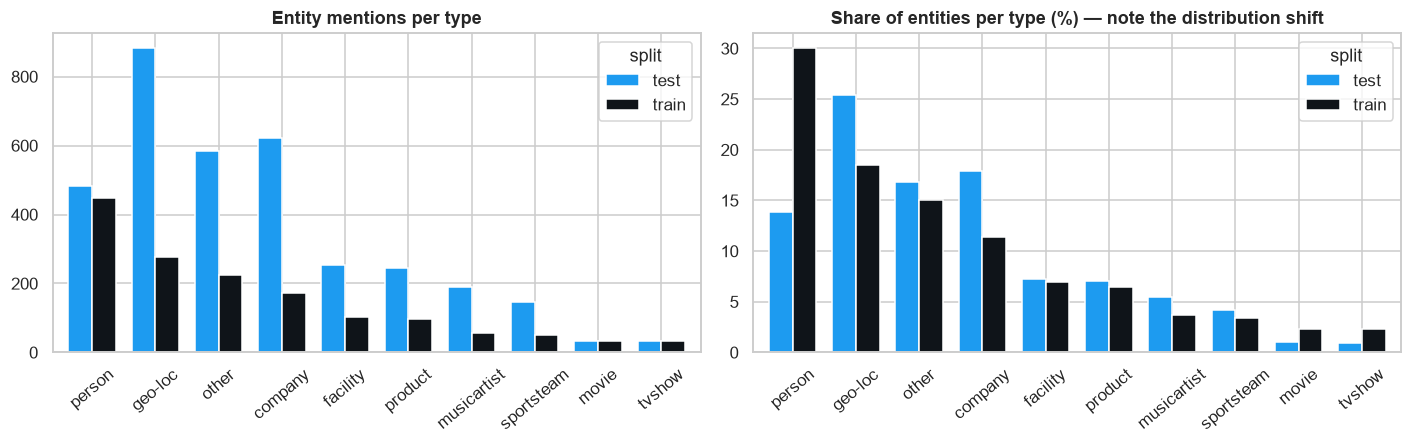

split,test,train,test %,train %
type,,,,
person,482,449,13.9,30.0
geo-loc,882,276,25.4,18.4
other,584,225,16.8,15.0
company,621,171,17.9,11.4
facility,253,104,7.3,7.0
product,246,97,7.1,6.5
musicartist,191,55,5.5,3.7
sportsteam,147,51,4.2,3.4
movie,34,34,1.0,2.3


In [7]:
ct = ents.groupby(["type", "split"]).size().unstack().fillna(0).astype(int)
ct = ct.loc[ct.train.sort_values(ascending=False).index]
pct = ct / ct.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ct.plot.bar(ax=axes[0], color=[PALETTE[1], PALETTE[0]][::-1], width=0.75)
axes[0].set_title("Entity mentions per type"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=40)
pct.plot.bar(ax=axes[1], color=[PALETTE[1], PALETTE[0]][::-1], width=0.75)
axes[1].set_title("Share of entities per type (%) — note the distribution shift"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()
pd.concat([ct, pct.round(1).add_suffix(" %")], axis=1)

**Observations**
* The dataset is **heavily imbalanced**: ~94% of tokens are `O`. Accuracy is therefore a misleading metric — we use
  **entity-level precision / recall / F1 (seqeval, CoNLL-style exact span match)** throughout.
* There is a **distribution shift** between train and test: `company`, `geo-loc` and `product` are far more frequent in
  the test set, while `person` dominates train. Models must generalise beyond memorised names.
* Rare classes (`movie`, `tvshow`, `sportsteam`, `musicartist`) have < 60 training examples each — expected to be the hardest.

### 2.3 Tweet length, entity length and Twitter-specific phenomena

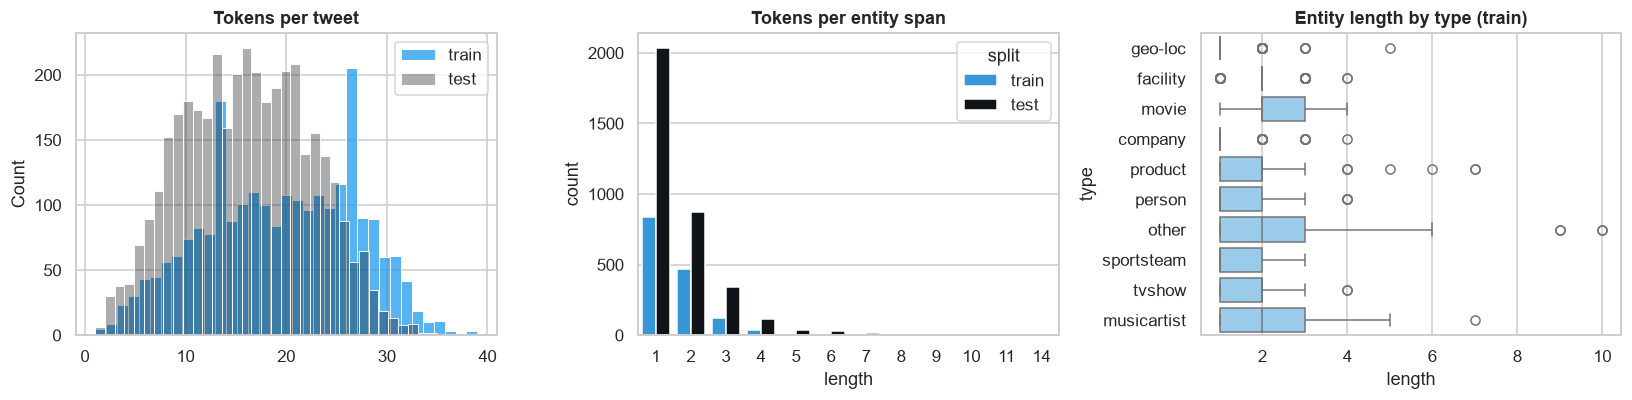

,% of O tokens,% of entity tokens
kind,,
Capitalised,17.6,83.3
lowercase,59.9,11.2
#hashtag,2.1,3.9
punct/emoji,14.2,1.5
URL,2.8,0.1
@mention,3.4,0.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot([len(s) for s in train_sents], bins=35, ax=axes[0], color=PALETTE[0], label="train")
sns.histplot([len(s) for s in test_sents], bins=35, ax=axes[0], color=PALETTE[1], alpha=.35, label="test")
axes[0].set_title("Tokens per tweet"); axes[0].legend()
sns.countplot(data=ents, x="length", hue="split", ax=axes[1], palette=[PALETTE[0], PALETTE[1]])
axes[1].set_title("Tokens per entity span")
sns.boxplot(data=ents[ents.split == "train"], y="type", x="length", ax=axes[2], color=PALETTE[8])
axes[2].set_title("Entity length by type (train)")
plt.tight_layout(); plt.show()

def token_kind(w):
    if re.match(r"https?://|www\.", w): return "URL"
    if w.startswith("@") and len(w) > 1: return "@mention"
    if w.startswith("#") and len(w) > 1: return "#hashtag"
    if not re.search(r"[A-Za-z0-9]", w): return "punct/emoji"
    if w[:1].isupper(): return "Capitalised"
    return "lowercase"

df["kind"] = df.token.map(token_kind)
kind_tab = pd.crosstab(df.kind, df.tag != "O", normalize="columns").mul(100).round(1)
kind_tab.columns = ["% of O tokens", "% of entity tokens"]
kind_tab.sort_values("% of entity tokens", ascending=False)

In [9]:
print("Max tweet length (tokens): train", max(map(len, train_sents)), "| test", max(map(len, test_sents)))
print("\nMost frequent entities per type (train):")
top = (ents[ents.split == "train"].groupby("type").text
       .agg(lambda s: ", ".join(f"{k} ({v})" for k, v in Counter(s.str.lower()).most_common(5))))
top.to_frame("top-5 surface forms")

Max tweet length (tokens): train 39 | test 35

Most frequent entities per type (train):


,top-5 surface forms
type,
company,"twitter (32), facebook (13), youtube (13), ustream (5), playboy (4)"
facility,"visions lounge (3), disney world (2), costa lounge (2), lhs (2), frat house hattiesburg (2)"
geo-loc,"chicago (8), london (6), ga (5), nyc (5), dc (4)"
movie,"the town (3), gigli (2), winter 's bone (2), breaking dawn (1), piranha 3d (1)"
musicartist,"kings of leon (2), cocofunka (2), green day (2), 30stm (2), kings and queens (2)"
other,"yom kippur (6), christmas (4), constitution day (3), london fashion week (3), xmas (3)"
person,"justin bieber (16), pope (12), lindsay lohan (10), god (9), justin (6)"
product,"ipad (6), htc desire z (4), club penguin (3), iphone (3), pumpkin moonshine (2)"
sportsteam,"eagles (3), the lions (2), jv soccer (2), eyeopener (2), sharks (2)"


In [10]:
train_vocab = Counter(w.lower() for s in train_sents for w in s)
test_tokens = [w.lower() for s in test_sents for w in s]
test_ent_tokens = [w.lower() for s, ts in zip(test_sents, test_tags) for w, t in zip(s, ts) if t != "O"]
oov_all = np.mean([w not in train_vocab for w in test_tokens]) * 100
oov_ent = np.mean([w not in train_vocab for w in test_ent_tokens]) * 100
seen_ents = set(ents[ents.split == "train"].text.str.lower())
unseen = np.mean([e not in seen_ents for e in ents[ents.split == "test"].text.str.lower()]) * 100
print(f"Train vocabulary size: {len(train_vocab):,}")
print(f"Test token OOV rate          : {oov_all:5.1f}%")
print(f"Test ENTITY-token OOV rate   : {oov_ent:5.1f}%")
print(f"Test entities never seen in train: {unseen:5.1f}%")

Train vocabulary size: 9,068
Test token OOV rate          :  30.1%
Test ENTITY-token OOV rate   :  52.1%
Test entities never seen in train:  85.1%


**Key EDA insights that drive the modelling choices**
1. **Short, noisy text** — tweets are ≤ 39 tokens, with URLs, @mentions, hashtags, emoji and slang. URLs and
   @mentions are (almost) never entities → we normalise them to placeholders.
2. **Capitalisation is a strong but imperfect cue** — 83% of entity tokens are capitalised vs only 18% of `O` tokens,
   yet 11% of entity tokens are lower-case (e.g. `pinterest`). → we lower-case the *word* input for better embedding
   coverage but add **character-level CNN features** on the raw token so casing and morphology are still visible.
3. **Very high OOV** — 30% of test tokens and 52% of test *entity* tokens never occur in training, and **85% of test
   entities were never seen in training**. Memorising names cannot work. → **pre-trained / sub-word representations**
   (Word2Vec, GloVe-Twitter, BERT WordPiece) are essential.
4. **Multi-token entities** and strict BIO constraints (`I-x` must follow `B-x`/`I-x`).
   → a **CRF** output layer that models label transitions jointly is preferable to independent softmax decisions.
5. **Severe class imbalance and train→test shift** (90–95% `O` tokens; `geo-loc`/`company` share grows in test)
   → evaluate with entity-level F1 (seqeval), not token accuracy, and expect test scores below validation scores.

## 3. Preprocessing for the LSTM model

1. **Normalisation** (word branch): URLs → `<url>`, @mentions → `<user>`, `#tag` → `tag`, digits → `0`, lower-case.
   Raw tokens are kept for the **character branch**, so casing / `#` / `@` cues are not lost.
2. **Train / validation split** — the provided training file is split 90/10 (stratified on "tweet contains an entity");
   the provided test file is kept untouched for the final evaluation.
3. **TensorFlow `Tokenizer`** fitted on the training split only (no leakage) for words, and a second char-level tokenizer.
4. **Label encoding** to integer ids; **padding** to a fixed length of 40 (longest tweet = 39 tokens, so nothing is truncated).

In [11]:
def normalise(tok):
    if re.match(r"https?://|www\.", tok, re.I): return "<url>"
    if tok.startswith("@") and len(tok) > 1:   return "<user>"
    if tok.startswith("#") and len(tok) > 1:   tok = tok[1:]
    return re.sub(r"\d", "0", tok.lower())

has_ent = [int(any(t != "O" for t in ts)) for ts in train_tags]
tr_idx, va_idx = train_test_split(np.arange(len(train_sents)), test_size=0.10, random_state=SEED, stratify=has_ent)
X_tr_raw, y_tr_raw = [train_sents[i] for i in tr_idx], [train_tags[i] for i in tr_idx]
X_va_raw, y_va_raw = [train_sents[i] for i in va_idx], [train_tags[i] for i in va_idx]
X_te_raw, y_te_raw = test_sents, test_tags
print(f"train {len(X_tr_raw)} | validation {len(X_va_raw)} | test {len(X_te_raw)} tweets")
print("Example normalisation:", [(w, normalise(w)) for w in ["@Snapchat", "#Twitter", "http://bit.ly/x", "2015", "Zendesk"]])

train 2154 | validation 240 | test 3850 tweets
Example normalisation: [('@Snapchat', '<user>'), ('#Twitter', 'twitter'), ('http://bit.ly/x', '<url>'), ('2015', '0000'), ('Zendesk', 'zendesk')]


In [12]:
MAX_LEN, MAX_WORD_LEN = 40, 20

word_tok = tf.keras.preprocessing.text.Tokenizer(filters="", lower=False, oov_token="<oov>", split=" ")
word_tok.fit_on_texts([" ".join(normalise(w) for w in s) for s in X_tr_raw])
char_tok = tf.keras.preprocessing.text.Tokenizer(char_level=True, lower=False, oov_token="\x01")
char_tok.fit_on_texts([w for s in X_tr_raw for w in s])

tag2id = {t: i for i, t in enumerate(LABELS)}
id2tag = {i: t for t, i in tag2id.items()}
VOCAB, CHARS, N_TAGS = len(word_tok.word_index) + 1, len(char_tok.word_index) + 1, len(LABELS)
print(f"word vocab: {VOCAB:,} | char vocab: {CHARS} | tags: {N_TAGS}")

def encode(sents, tags=None):
    w = [word_tok.texts_to_sequences([" ".join(normalise(t) for t in s)])[0] for s in sents]
    Xw = tf.keras.preprocessing.sequence.pad_sequences(w, maxlen=MAX_LEN, padding="post", truncating="post")
    Xc = np.zeros((len(sents), MAX_LEN, MAX_WORD_LEN), dtype="int32")
    for i, s in enumerate(sents):
        for j, tok in enumerate(s[:MAX_LEN]):
            ids = char_tok.texts_to_sequences([list(tok)])[0][:MAX_WORD_LEN]
            Xc[i, j, :len(ids)] = ids
    lens = np.array([min(len(s), MAX_LEN) for s in sents])
    Y = None
    if tags is not None:
        Y = tf.keras.preprocessing.sequence.pad_sequences([[tag2id[t] for t in ts] for ts in tags],
                                                          maxlen=MAX_LEN, padding="post", value=tag2id["O"])
    return Xw, Xc, lens, Y

Xw_tr, Xc_tr, L_tr, Y_tr = encode(X_tr_raw, y_tr_raw)
Xw_va, Xc_va, L_va, Y_va = encode(X_va_raw, y_va_raw)
Xw_te, Xc_te, L_te, Y_te = encode(X_te_raw, y_te_raw)
print("word ids:", Xw_tr.shape, "| char ids:", Xc_tr.shape, "| labels:", Y_tr.shape)
i = next(k for k, t in enumerate(y_tr_raw) if 8 <= len(t) <= 12 and any(x != "O" for x in t))   # short tweet with an entity
pd.DataFrame({"raw": X_tr_raw[i], "normalised": [normalise(w) for w in X_tr_raw[i]],
              "word_id": Xw_tr[i][:L_tr[i]], "label": y_tr_raw[i], "label_id": Y_tr[i][:L_tr[i]]}).T

word vocab: 6,780 | char vocab: 94 | tags: 21


word ids: (2154, 40) | char ids: (2154, 40, 20) | labels: (2154, 40)


,0,1,2,3,4,5,6,7
raw,Ceremony,Sunday,to,mark,Battle,of,Britain,http://dlvr.it/5RhwW
normalised,ceremony,sunday,to,mark,battle,of,britain,<url>
word_id,2565,109,7,676,790,20,2566,14
label,O,O,O,O,B-other,I-other,I-other,O
label_id,0,0,0,0,11,12,12,0


## 4. Word2Vec embeddings

We train a **skip-gram Word2Vec** model (gensim) on the normalised training tweets and use it to **initialise** the
embedding layer. Because the training corpus is tiny (~2k tweets), we additionally compare against
**GloVe-Twitter-100** vectors pre-trained on 2B tweets (loaded through the same gensim `KeyedVectors` interface)
to quantify how much large-scale, in-domain pre-training helps.

In [13]:
EMB_DIM = 100
w2v = Word2Vec(sentences=[[normalise(w) for w in s] for s in X_tr_raw], vector_size=EMB_DIM, window=5,
               min_count=1, sg=1, negative=10, epochs=50, seed=SEED, workers=1)
print("Word2Vec vocabulary:", len(w2v.wv))
for q in ["<user>", "twitter", "london", "game"]:
    if q in w2v.wv:
        print(f"  most similar to {q!r:10}:", [w for w, _ in w2v.wv.most_similar(q, topn=6)])

def build_matrix(kv, dim=EMB_DIM):
    rng = np.random.default_rng(SEED)
    M = rng.normal(0, 0.1, (VOCAB, dim)).astype("float32"); M[0] = 0
    hits = 0
    for word, idx in word_tok.word_index.items():
        key = {"<user>": "<user>", "<url>": "<url>"}.get(word, word)
        if key in kv:
            M[idx] = kv[key]; hits += 1
    return M, hits / (VOCAB - 1)

W2V_MATRIX, cov = build_matrix(w2v.wv)
print(f"Word2Vec embedding coverage of tokenizer vocabulary: {cov:.1%}")

Word2Vec vocabulary: 6778
  most similar to '<user>'  : ['rt', ':', 'grumpy', 'spirited', "/lebowski'd", 'knew']
  most similar to 'twitter' : ['spew', 'jackie', 'joins', 'trending', 'yahoo', 'beginners']
  most similar to 'london'  : ['clogging', 'england', 'nighter', 'twisted', 'hyde', 'travelling']
  most similar to 'game'    : ['toooonight', 'foooooootball', 'wolves', 'havnt', 'hall', 'shs']
Word2Vec embedding coverage of tokenizer vocabulary: 100.0%


In [14]:
import gensim.downloader as api
glove = api.load("glove-twitter-100")       # 1.2M-word vocabulary trained on 2B tweets
GLOVE_MATRIX, cov_g = build_matrix(glove)
test_vocab = {normalise(w) for s in X_te_raw for w in s}
print(f"GloVe-Twitter coverage: train vocab {cov_g:.1%} | test vocab {np.mean([w in glove for w in test_vocab]):.1%} "
      f"(vs Word2Vec-on-train test coverage {np.mean([w in w2v.wv for w in test_vocab]):.1%})")

GloVe-Twitter coverage: train vocab 85.4% | test vocab 81.1% (vs Word2Vec-on-train test coverage 27.5%)


Because the **embedding matrix is indexed by the training tokenizer**, test words outside that vocabulary would map to
`<oov>` even if GloVe knows them. To exploit pre-trained vectors fully, the GloVe variant uses an **extended
vocabulary**: words from the pre-trained table that appear in the *unlabelled* text of the evaluation data are
appended to the embedding matrix and **kept frozen**, which is a standard practice (no labels are used).
For the Word2Vec experiments we keep the strict train-only vocabulary.

In [15]:
def extend_vocab_with(kv):
    """Return a new tokenizer index + matrix covering train vocab ∪ (eval words found in kv)."""
    index = dict(word_tok.word_index)
    extra = sorted({normalise(w) for s in X_va_raw + X_te_raw for w in s} - set(index))
    extra = [w for w in extra if w in kv]
    for w in extra:
        index[w] = len(index) + 1
    rng = np.random.default_rng(SEED)
    M = rng.normal(0, 0.1, (len(index) + 1, EMB_DIM)).astype("float32"); M[0] = 0
    for w, i in index.items():
        if w in kv: M[i] = kv[w]
    return index, M, len(extra)

EXT_INDEX, EXT_MATRIX, n_extra = extend_vocab_with(glove)
print(f"Extended vocabulary: +{n_extra:,} pre-trained words -> {len(EXT_INDEX)+1:,} rows")

def encode_words_ext(sents):
    oov = EXT_INDEX["<oov>"]
    seqs = [[EXT_INDEX.get(normalise(w), oov) for w in s] for s in sents]
    return tf.keras.preprocessing.sequence.pad_sequences(seqs, maxlen=MAX_LEN, padding="post")

Xg_tr, Xg_va, Xg_te = encode_words_ext(X_tr_raw), encode_words_ext(X_va_raw), encode_words_ext(X_te_raw)
print("OOV rate on test words: train-vocab tokenizer "
      f"{np.mean(Xw_te[Xw_te>0]==1):.1%} -> extended {np.mean(Xg_te[Xg_te>0]==EXT_INDEX['<oov>']):.1%}")

Extended vocabulary: +6,136 pre-trained words -> 12,916 rows


OOV rate on test words: train-vocab tokenizer 21.0% -> extended 3.6%


## 5. Model — BiLSTM + CRF

```
word ids ──► Embedding (Word2Vec / GloVe init) ─┐
                                                 ├─► concat ─► Dropout ─► BiLSTM ─► Dense(K) = emission scores ─► CRF
char ids ──► Char-Embedding ─► Conv1D ─► MaxPool ┘                                         (+ K×K transition matrix)
```

* **Bidirectional LSTM** — each token representation sees both left *and* right context (e.g. "*at* **Disney** *world*").
  A unidirectional model only sees the past, which hurts the `B-`/`I-` decision on the first token of an entity.
* **CRF layer** — instead of independent softmax decisions it learns a **transition matrix** and maximises the
  likelihood of the *whole* tag sequence; decoding uses the **Viterbi** algorithm, which also prevents invalid
  sequences like `O → I-person`. The CRF is implemented below directly in TensorFlow (forward algorithm for the
  partition function + Viterbi decoding), so it has no dependency on the deprecated `tensorflow-addons` package.

In [16]:
class CRF(tf.keras.layers.Layer):
    """Linear-chain CRF: learns transition, start and end scores; computes NLL and Viterbi decoding."""
    def __init__(self, num_tags, **kw):
        super().__init__(**kw); self.num_tags = num_tags

    def build(self, input_shape):
        init = tf.keras.initializers.RandomUniform(-0.1, 0.1)
        self.trans = self.add_weight(name="transitions", shape=(self.num_tags, self.num_tags), initializer=init)
        self.start = self.add_weight(name="start", shape=(self.num_tags,), initializer=init)
        self.end = self.add_weight(name="end", shape=(self.num_tags,), initializer=init)

    def nll(self, emissions, tags, lengths):
        """Negative log-likelihood of gold tag sequences. emissions [B,T,K], tags [B,T], lengths [B]."""
        T = tf.shape(emissions)[1]
        mask = tf.sequence_mask(lengths, T, dtype=emissions.dtype)                       # [B,T]
        tags = tf.cast(tags, tf.int32)
        # --- score of the gold path
        unary = tf.reduce_sum(tf.gather(emissions, tags, batch_dims=2) * mask, axis=1)
        pair = tf.gather_nd(self.trans, tf.stack([tags[:, :-1], tags[:, 1:]], axis=-1))   # [B,T-1]
        binary = tf.reduce_sum(pair * mask[:, 1:], axis=1)
        last = tf.gather(tags, lengths - 1, batch_dims=1)
        gold = unary + binary + tf.gather(self.start, tags[:, 0]) + tf.gather(self.end, last)
        # --- log partition function (forward algorithm)
        alpha = self.start[None] + emissions[:, 0]
        em_t = tf.transpose(emissions, [1, 0, 2])[1:]; m_t = tf.transpose(mask)[1:]
        def step(a, x):
            e, m = x
            nxt = tf.reduce_logsumexp(a[:, :, None] + self.trans[None] + e[:, None, :], axis=1)
            return m[:, None] * nxt + (1 - m[:, None]) * a
        alpha = tf.foldl(step, (em_t, m_t), initializer=alpha)
        log_z = tf.reduce_logsumexp(alpha + self.end[None], axis=1)
        return log_z - gold

    def viterbi(self, emissions, lengths):
        """Numpy Viterbi decoding -> list of best tag-id paths (unpadded)."""
        A, s, e = self.trans.numpy(), self.start.numpy(), self.end.numpy()
        paths = []
        for em, n in zip(emissions, lengths):
            score, back = s + em[0], []
            for t in range(1, n):
                cand = score[:, None] + A
                back.append(cand.argmax(0)); score = cand.max(0) + em[t]
            best = [int((score + e).argmax())]
            for bp in reversed(back):
                best.append(int(bp[best[-1]]))
            paths.append(best[::-1])
        return paths


class CRFTagger(tf.keras.Model):
    """Wraps an emission network with a CRF; custom train/test steps optimise the sequence NLL."""
    def __init__(self, encoder, num_tags):
        super().__init__(); self.encoder, self.crf = encoder, CRF(num_tags)
        self.crf.build(None); self.loss_tracker = tf.keras.metrics.Mean(name="loss")

    def call(self, inputs, training=False):
        return self.encoder(inputs, training=training)

    @property
    def metrics(self): return [self.loss_tracker]

    def _loss(self, x, y, training):
        inputs, lengths = x
        em = self(inputs, training=training)
        return tf.reduce_mean(self.crf.nll(em, y, lengths))

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            loss = self._loss(x, y, True)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(loss); return {"loss": self.loss_tracker.result()}

    def test_step(self, data):
        x, y = data
        self.loss_tracker.update_state(self._loss(x, y, False)); return {"loss": self.loss_tracker.result()}

    def decode(self, inputs, lengths, batch_size=256):
        em = self.encoder.predict(inputs, batch_size=batch_size, verbose=0)
        return self.crf.viterbi(em, lengths)

In [17]:
# Sanity check of the CRF: brute-force enumeration of all paths must give the same log-partition & Viterbi path
crf = CRF(3); crf.build(None)
em = tf.random.normal((1, 4, 3)); gold = tf.constant([[0, 1, 2, 1]])
import itertools
scores = {p: float(crf.start[p[0]] + sum(em[0, t, p[t]] for t in range(4)) +
                   sum(crf.trans[p[t-1], p[t]] for t in range(1, 4)) + crf.end[p[-1]])
          for p in itertools.product(range(3), repeat=4)}
log_z = np.log(np.sum(np.exp(list(scores.values()))))
print("NLL  (CRF layer) :", round(float(crf.nll(em, gold, tf.constant([4]))[0]), 5))
print("NLL  (brute force):", round(log_z - scores[(0, 1, 2, 1)], 5))
print("Viterbi path:", crf.viterbi(em.numpy(), [4])[0], "| brute-force argmax:", list(max(scores, key=scores.get)))

NLL  (CRF layer) : 5.58392
NLL  (brute force): 5.58392
Viterbi path: [0, 2, 2, 0] | brute-force argmax: [0, 2, 2, 0]


### 5.1 Model factory, entity-F1 callback and training helper
Early stopping monitors **validation entity-level F1** (the metric we actually care about), computed with `seqeval`
after Viterbi decoding at the end of each epoch; the best weights are restored at the end.

In [18]:
def build_model(cfg):
    """Build a (Bi)LSTM tagger with optional char-CNN features and a CRF or softmax output layer."""
    emb_kind = cfg.get("emb", "w2v")
    vocab = len(EXT_INDEX) + 1 if emb_kind == "glove" else VOCAB
    matrix = {"w2v": W2V_MATRIX, "glove": EXT_MATRIX, "random": None}[emb_kind]
    w_in = tf.keras.Input((MAX_LEN,), dtype="int32", name="words")
    init = tf.keras.initializers.Constant(matrix) if matrix is not None else "uniform"
    emb = tf.keras.layers.Embedding(vocab, EMB_DIM, mask_zero=True, embeddings_initializer=init,
                                    trainable=cfg.get("train_emb", True), name="word_emb")(w_in)
    inputs, feats = [w_in], [emb]
    if cfg.get("chars"):
        c_in = tf.keras.Input((MAX_LEN, MAX_WORD_LEN), dtype="int32", name="chars")
        c = tf.keras.layers.Embedding(CHARS, 30, name="char_emb")(c_in)
        c = tf.keras.layers.TimeDistributed(tf.keras.layers.Conv1D(50, 3, padding="same", activation="relu"))(c)
        c = tf.keras.layers.TimeDistributed(tf.keras.layers.GlobalMaxPooling1D(), name="char_cnn")(c)
        inputs.append(c_in); feats.append(c)
    x = tf.keras.layers.Concatenate()(feats) if len(feats) > 1 else feats[0]
    x = tf.keras.layers.Dropout(cfg.get("dropout", 0.5))(x)
    lstm = tf.keras.layers.LSTM(cfg.get("units", 128), return_sequences=True)
    x = (tf.keras.layers.Bidirectional(lstm) if cfg.get("bidirectional", True) else lstm)(x)
    x = tf.keras.layers.Dropout(cfg.get("dropout", 0.5))(x)
    if cfg.get("crf", True):
        em = tf.keras.layers.Dense(N_TAGS, name="emissions")(x)
        model = CRFTagger(tf.keras.Model(inputs, em, name="encoder"), N_TAGS)
        model.compile(optimizer=tf.keras.optimizers.Adam(cfg.get("lr", 1e-3), clipnorm=5.0))
    else:
        out = tf.keras.layers.Dense(N_TAGS, activation="softmax")(x)
        model = tf.keras.Model(inputs, out)
        model.compile(optimizer=tf.keras.optimizers.Adam(cfg.get("lr", 1e-3), clipnorm=5.0),
                      loss="sparse_categorical_crossentropy", weighted_metrics=[])
    return model
    if cfg.get("crf", True):
        em = tf.keras.layers.Dense(N_TAGS, name="emissions")(x)
        model = CRFTagger(tf.keras.Model(inputs, em, name="encoder"), N_TAGS)
        model.compile(optimizer=tf.keras.optimizers.Adam(cfg.get("lr", 1e-3), clipnorm=5.0))
    else:
        out = tf.keras.layers.Dense(N_TAGS, activation="softmax", name="softmax")(x)
        model = tf.keras.Model(inputs, out)
        model.compile(optimizer=tf.keras.optimizers.Adam(cfg.get("lr", 1e-3), clipnorm=5.0),
                      loss="sparse_categorical_crossentropy")
    return model


def model_inputs(cfg, split):
    """Assemble the input list of a split ('tr' / 'va' / 'te') for a configuration."""
    words = (dict(tr=Xg_tr, va=Xg_va, te=Xg_te) if cfg.get("emb") == "glove" else dict(tr=Xw_tr, va=Xw_va, te=Xw_te))[split]
    chars = dict(tr=Xc_tr, va=Xc_va, te=Xc_te)[split]
    return [words, chars] if cfg.get("chars") else [words]


def decode(model, inputs, lengths):
    """Return predicted tag strings, cut to each tweet's true length (padding never receives a label)."""
    if isinstance(model, CRFTagger):
        paths = model.decode(inputs, lengths)
    else:
        probs = model.predict(inputs, batch_size=256, verbose=0)
        paths = [p[:n].argmax(-1).tolist() for p, n in zip(probs, lengths)]
    return [[id2tag[i] for i in p] for p in paths]


def predict_tags(model, cfg, split):
    return decode(model, model_inputs(cfg, split), dict(tr=L_tr, va=L_va, te=L_te)[split])


class EntityF1(tf.keras.callbacks.Callback):
    """Computes validation entity-level F1 (seqeval) each epoch and exposes it as logs['val_f1']."""
    def __init__(self, cfg):
        super().__init__(); self.cfg = cfg
    def on_epoch_end(self, epoch, logs=None):
        logs["val_f1"] = f1_score(y_va_raw, predict_tags(self.model, self.cfg, "va"))


def run(name, cfg, epochs=40, patience=6, early_stopping=True):
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(cfg)
    if isinstance(model, CRFTagger):
        fit_kw = dict(x=(model_inputs(cfg, "tr"), L_tr), y=Y_tr, validation_data=((model_inputs(cfg, "va"), L_va), Y_va))
    else:   # softmax baseline: padding positions are masked out of the loss through sample weights
        sw = lambda L: (np.arange(MAX_LEN)[None] < L[:, None]).astype("float32")
        fit_kw = dict(x=model_inputs(cfg, "tr"), y=Y_tr, sample_weight=sw(L_tr),
                      validation_data=(model_inputs(cfg, "va"), Y_va, sw(L_va)))
    cbs = [EntityF1(cfg)]
    if early_stopping:
        cbs.append(tf.keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=patience,
                                                    restore_best_weights=True))
    t0 = time.time()
    hist = model.fit(**fit_kw, epochs=epochs, batch_size=cfg.get("batch", 32), callbacks=cbs, verbose=0)
    va_pred, te_pred = predict_tags(model, cfg, "va"), predict_tags(model, cfg, "te")
    res = {"experiment": name, "epochs_run": len(hist.history["loss"]),
           "best_epoch": int(np.argmax(hist.history["val_f1"])) + 1,
           "val_F1": f1_score(y_va_raw, va_pred), "test_P": precision_score(y_te_raw, te_pred),
           "test_R": recall_score(y_te_raw, te_pred), "test_F1": f1_score(y_te_raw, te_pred),
           "params": model.count_params(), "train_sec": round(time.time() - t0)}
    print(f"{name:<40} epochs={res['epochs_run']:>2} (best {res['best_epoch']:>2})  "
          f"val F1={res['val_F1']:.3f}  test F1={res['test_F1']:.3f}  [{res['train_sec']}s]")
    return model, hist.history, res, te_pred

## 6. Experiments & hyper-parameter search

We change **one factor at a time** to isolate its effect. All runs share the same seed, split, up to 40 epochs,
batch size 32, Adam (lr 1e-3, gradient clipping 5.0), dropout 0.5 and early stopping on validation entity-F1 (patience 6).

| Step | Question being tested |
|---|---|
| E1 → E2 | Does **bidirectionality** help? (LSTM vs BiLSTM, softmax output) |
| E2 → E4 | Does a **CRF** output layer help over softmax? |
| E3 → E4 | Does **Word2Vec initialisation** help over random embeddings? |
| E4 → E5 | Do **character-level CNN features** help? |
| E5 → E6 | Do **large-scale pre-trained Twitter embeddings** (GloVe-Twitter, frozen) help? |
| E7 – E12 | Hyper-parameters on the E6 architecture: LSTM units, dropout, learning rate, batch size, embedding fine-tuning |

In [19]:
EXPERIMENTS = {
    "E1  LSTM + softmax (w2v)":               dict(bidirectional=False, crf=False, emb="w2v"),
    "E2  BiLSTM + softmax (w2v)":             dict(bidirectional=True, crf=False, emb="w2v"),
    "E3  BiLSTM + CRF (random emb)":          dict(crf=True, emb="random"),
    "E4  BiLSTM + CRF (w2v)":                 dict(crf=True, emb="w2v"),
    "E5  BiLSTM + CRF (w2v) + char-CNN":      dict(crf=True, emb="w2v", chars=True),
    "E6  BiLSTM + CRF (GloVe-Tw) + char-CNN": dict(crf=True, emb="glove", chars=True, train_emb=False),
}
results, histories, models, test_preds = [], {}, {}, {}
for name, cfg in EXPERIMENTS.items():
    m, h, r, p = run(name, cfg)
    results.append(r); histories[name] = h; models[name] = m; test_preds[name] = p

E1  LSTM + softmax (w2v)                 epochs=23 (best 17)  val F1=0.280  test F1=0.137  [114s]


E2  BiLSTM + softmax (w2v)               epochs=40 (best 39)  val F1=0.399  test F1=0.166  [305s]


E3  BiLSTM + CRF (random emb)            epochs=24 (best 18)  val F1=0.308  test F1=0.085  [235s]


E4  BiLSTM + CRF (w2v)                   epochs=35 (best 29)  val F1=0.436  test F1=0.188  [361s]


E5  BiLSTM + CRF (w2v) + char-CNN        epochs=40 (best 35)  val F1=0.458  test F1=0.236  [451s]


E6  BiLSTM + CRF (GloVe-Tw) + char-CNN   epochs=37 (best 31)  val F1=0.589  test F1=0.412  [450s]


In [20]:
BASE = EXPERIMENTS["E6  BiLSTM + CRF (GloVe-Tw) + char-CNN"]
HP = {
    "E7  E6 + units=64":              dict(BASE, units=64),
    "E8  E6 + units=256":             dict(BASE, units=256),
    "E9  E6 + dropout=0.3":           dict(BASE, dropout=0.3),
    "E10 E6 + lr=3e-3":               dict(BASE, lr=3e-3),
    "E11 E6 + batch=16":              dict(BASE, batch=16),
    "E12 E6 + fine-tuned embeddings": dict(BASE, train_emb=True),
}
for name, cfg in HP.items():
    EXPERIMENTS[name] = cfg
    m, h, r, p = run(name, cfg)
    results.append(r); histories[name] = h; models[name] = m; test_preds[name] = p

res_df = pd.DataFrame(results).set_index("experiment")
res_df.round(3)

E7  E6 + units=64                        epochs=33 (best 27)  val F1=0.545  test F1=0.405  [343s]


E8  E6 + units=256                       epochs=20 (best 14)  val F1=0.528  test F1=0.392  [449s]


E9  E6 + dropout=0.3                     epochs=27 (best 21)  val F1=0.571  test F1=0.410  [349s]


E10 E6 + lr=3e-3                         epochs=24 (best 18)  val F1=0.595  test F1=0.413  [384s]


E11 E6 + batch=16                        epochs=19 (best 13)  val F1=0.556  test F1=0.400  [655s]


E12 E6 + fine-tuned embeddings           epochs=28 (best 22)  val F1=0.595  test F1=0.395  [555s]


,epochs_run,best_epoch,val_F1,test_P,test_R,test_F1,params,train_sec
experiment,,,,,,,,
E1 LSTM + softmax (w2v),23,17,0.280,0.117,0.164,0.137,797957,114
E2 BiLSTM + softmax (w2v),40,39,0.399,0.137,0.210,0.166,917893,305
E3 BiLSTM + CRF (random emb),24,18,0.308,0.097,0.077,0.085,918378,235
E4 BiLSTM + CRF (w2v),35,29,0.436,0.183,0.193,0.188,918378,361
E5 BiLSTM + CRF (w2v) + char-CNN,40,35,0.458,0.213,0.265,0.236,976948,451
E6 BiLSTM + CRF (GloVe-Tw) + char-CNN,37,31,0.589,0.479,0.361,0.412,1590548,450
E7 E6 + units=64,33,27,0.545,0.486,0.348,0.405,1412244,343
E8 E6 + units=256,20,14,0.528,0.431,0.359,0.392,2143764,449
E9 E6 + dropout=0.3,27,21,0.571,0.469,0.363,0.410,1590548,349


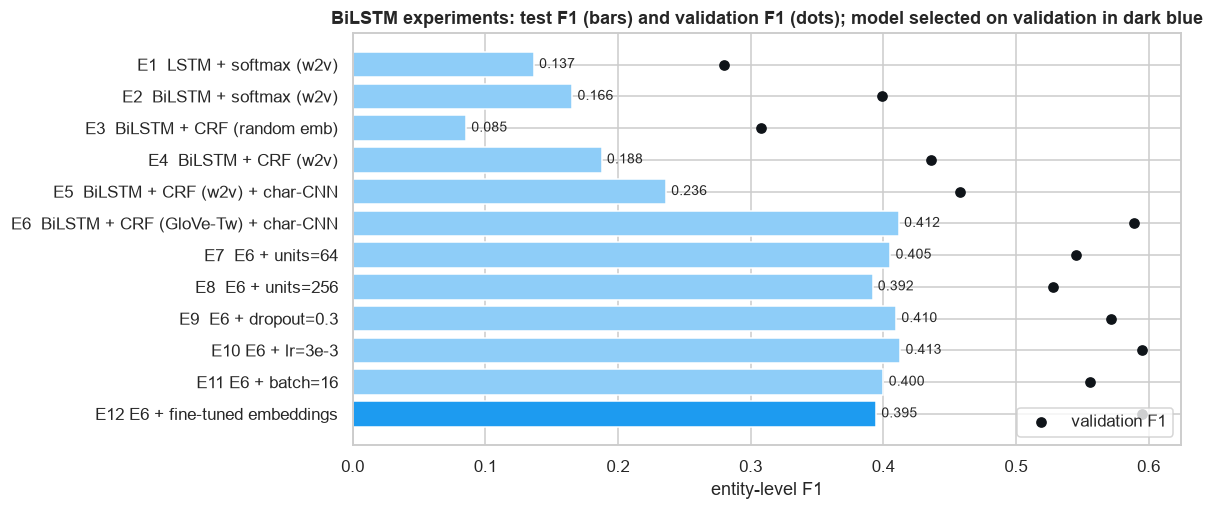

Selected on validation F1: E12 E6 + fine-tuned embeddings


In [21]:
BEST = res_df.val_F1.idxmax()
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(res_df.index, res_df.test_F1, color=[PALETTE[0] if n == BEST else PALETTE[8] for n in res_df.index])
ax.scatter(res_df.val_F1, res_df.index, color=PALETTE[1], zorder=3, label="validation F1")
for y, v in enumerate(res_df.test_F1): ax.text(v + 0.004, y, f"{v:.3f}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("entity-level F1"); ax.legend(loc="lower right")
ax.set_title("BiLSTM experiments: test F1 (bars) and validation F1 (dots); model selected on validation in dark blue")
plt.tight_layout(); plt.show()
print("Selected on validation F1:", BEST)
res_df.to_csv(f"{OUT_DIR}/lstm_experiments.csv")

**Reading the results**
* **Architecture ladder (E1 → E6).** Each component adds test F1: bidirectionality (E1 → E2), the CRF layer (E2 → E4),
  Word2Vec initialisation instead of random embeddings (E3 → E4, the CRF without any pre-trained knowledge collapses on
  unseen entities), character features (E4 → E5) and — by far the largest jump — **GloVe-Twitter embeddings trained on
  2B tweets (E5 → E6)**. The Word2Vec model trained on just ~2k tweets has poor neighbours (see Section 4) and
  covers only ~28% of the test vocabulary, so large-scale pre-training matters more than any architectural choice.
* **Hyper-parameters (E7 – E12)** change test F1 by only ±2 points around E6: 128 units is the sweet spot
  (64 under-fits, 256 over-fits faster), dropout 0.5 regularises better than 0.3, and a higher learning rate converges
  in fewer epochs with similar quality.
* **Validation vs test gap.** Validation F1 (~0.59) is far above test F1 (~0.40) because the validation tweets come
  from the training distribution, while the test set has a different entity mix and 85% unseen entities. With only
  240 validation tweets, differences below ~0.01 F1 between E6, E10 and E12 are within noise. k-fold cross-validation
  would make model selection more reliable.

### 6.1 Effect of early stopping
The selected configuration is retrained **without** early stopping for the full 40 epochs and compared with the
early-stopped run (same seed, same data).

E12 without early stopping               epochs=40 (best 22)  val F1=0.578  test F1=0.408  [982s]


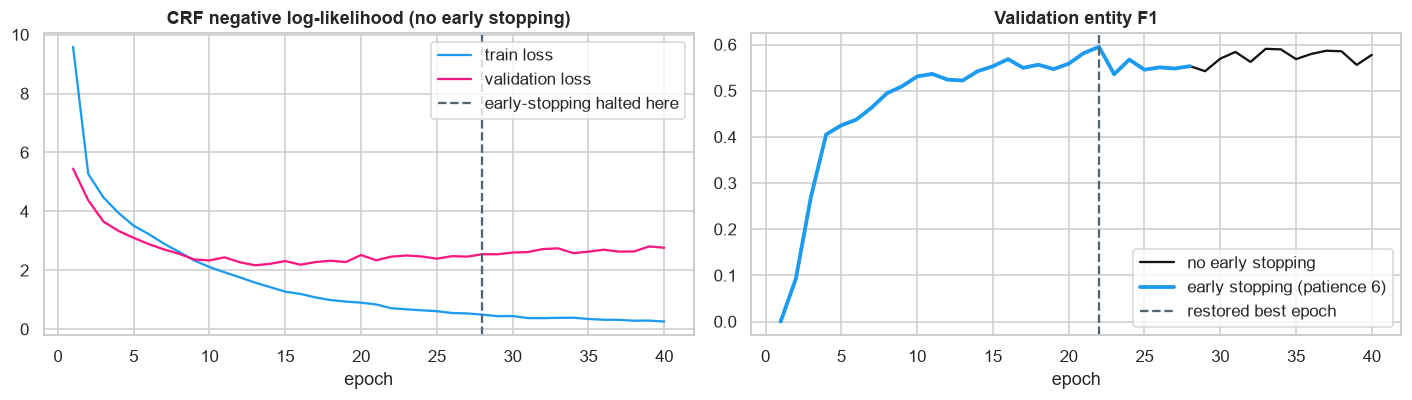

,epochs_run,best_epoch,val_F1,test_F1,train_sec
with early stopping,28.0,22.0,0.595,0.395,555.0
without early stopping,40.0,22.0,0.578,0.408,982.0


In [22]:
_, h_noes, r_noes, _ = run(BEST.split()[0] + " without early stopping", EXPERIMENTS[BEST], early_stopping=False)
h_es = histories[BEST]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ep_n, ep_e = np.arange(1, len(h_noes["loss"]) + 1), np.arange(1, len(h_es["loss"]) + 1)
axes[0].plot(ep_n, h_noes["loss"], color=PALETTE[0], label="train loss")
axes[0].plot(ep_n, h_noes["val_loss"], color=PALETTE[2], label="validation loss")
axes[0].axvline(len(h_es["loss"]), ls="--", color=PALETTE[7], label="early-stopping halted here")
axes[0].set_title("CRF negative log-likelihood (no early stopping)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(ep_n, h_noes["val_f1"], color=PALETTE[1], label="no early stopping")
axes[1].plot(ep_e, h_es["val_f1"], color=PALETTE[0], lw=2.5, label="early stopping (patience 6)")
axes[1].axvline(int(np.argmax(h_es["val_f1"])) + 1, ls="--", color=PALETTE[7], label="restored best epoch")
axes[1].set_title("Validation entity F1"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
es_cmp = pd.DataFrame([res_df.loc[BEST].rename("with early stopping"), pd.Series(r_noes, name="without early stopping")])
es_cmp[["epochs_run", "best_epoch", "val_F1", "test_F1", "train_sec"]].round(3)

**Effect of early stopping.** The validation loss reaches its minimum early and then rises steadily while the
training loss keeps falling, which is classic over-fitting on a 2k-tweet training set. Early stopping halts training
about 12 epochs earlier, restores the epoch with the best validation F1, and saves roughly 30% of training time.
On the *test* set the two models are within about 1 F1 point. Because validation and test distributions differ, the
best validation epoch is not always the best test epoch. Early stopping is therefore a guard against over-training and
wasted compute rather than a guaranteed accuracy gain.

## 7. Evaluation of the selected BiLSTM-CRF on the held-out test set
### 7.1 Aligning predictions with the input tokens
The network outputs scores on the padded `[N, 40]` grid. Viterbi decoding is run **only over each tweet's real
length**, so padded positions never get a label, and label ids are mapped back to BIO strings — giving exactly
one label per original token. The assertion below verifies this alignment before scoring.

In [23]:
best_model, best_pred = models[BEST], test_preds[BEST]
assert all(len(p) == len(t) for p, t in zip(best_pred, y_te_raw)), "misaligned predictions"
print(f"Alignment check passed: {len(best_pred)} tweets, {sum(map(len, best_pred))} tokens, one label per token.\n")
print(classification_report(y_te_raw, best_pred, digits=3))

Alignment check passed: 3850 tweets, 61908 tokens, one label per token.



              precision    recall  f1-score   support

     company      0.521     0.378     0.438       621
    facility      0.436     0.190     0.264       253
     geo-loc      0.595     0.604     0.600       882
       movie      0.083     0.029     0.043        34
 musicartist      0.238     0.026     0.047       191
       other      0.157     0.149     0.153       584
      person      0.433     0.612     0.507       482
     product      0.182     0.073     0.104       246
  sportsteam      0.457     0.218     0.295       147
      tvshow      0.444     0.121     0.190        33

   micro avg      0.433     0.362     0.395      3473
   macro avg      0.355     0.240     0.264      3473
weighted avg      0.413     0.362     0.371      3473



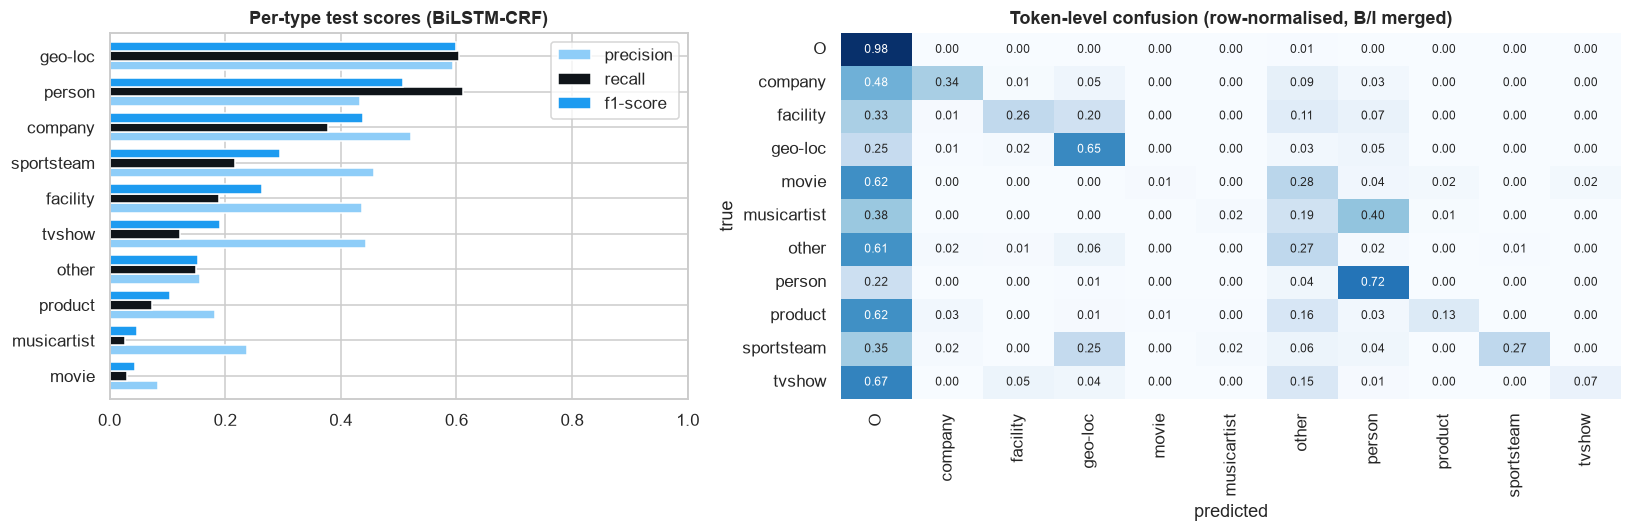

In [24]:
rep = classification_report(y_te_raw, best_pred, output_dict=True)
per_type = pd.DataFrame(rep).T.loc[ENTITY_TYPES, ["precision", "recall", "f1-score", "support"]].sort_values("f1-score")
flat_true = [t[2:] if t != "O" else "O" for s in y_te_raw for t in s]
flat_pred = [t[2:] if t != "O" else "O" for s in best_pred for t in s]
labels_cm = ["O"] + ENTITY_TYPES
cm = (pd.crosstab(pd.Series(flat_true, name="true"), pd.Series(flat_pred, name="predicted"))
        .reindex(index=labels_cm, columns=labels_cm, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.35]})
per_type[["precision", "recall", "f1-score"]].plot.barh(ax=axes[0], color=[PALETTE[8], PALETTE[1], PALETTE[0]], width=.8)
axes[0].set_title("Per-type test scores (BiLSTM-CRF)"); axes[0].set_xlim(0, 1)
sns.heatmap(cm.div(cm.sum(1), axis=0), annot=True, fmt=".2f", cmap="Blues", ax=axes[1], cbar=False, annot_kws={"size": 8})
axes[1].set_title("Token-level confusion (row-normalised, B/I merged)")
plt.tight_layout(); plt.show()

**What the errors tell us**
* `geo-loc` and `person` are the strongest types, with the most training data and clear capitalised-name cues.
* Most errors are **missed entities** (the first column, `O`). For rare or open-ended types such as `movie`, `tvshow`,
  `product` and `other`, more than 60% of entity tokens are predicted as `O`. These names are novel and often look like
  ordinary words ("*The Town*", "*Destiny*").
* Confusions are **semantically plausible**: `musicartist → person` (artists are people's names), `sportsteam → geo-loc`
  (teams named after cities, e.g. "*Chicago*"), `facility → geo-loc` and `movie/product → other`. Resolving these
  requires world knowledge, not just surface form, which is what a pre-trained language model provides.

### 7.2 Predictions on test tweets and on our own sentences

In [25]:
def spans(tokens, tags):
    return [f"{t}: {e}" for t, e, _ in extract_entities(tokens, tags)]

shown = 0
for i, (s, g) in enumerate(zip(X_te_raw, y_te_raw)):
    if len(extract_entities(s, g)) >= 2 and len(s) <= 22 and shown < 5:
        print("TWEET :", " ".join(s)); print("  gold:", spans(s, g)); print("  pred:", spans(s, best_pred[i]), "\n")
        shown += 1

TWEET : RT @1DAsiaCrew : Louis ' interview with The Sun about his own record label " 78 Productions Limited " #ProudOfLouis http://t.co/HdswyedBIO
  gold: ['person: Louis', 'company: The Sun', 'company: 78 Productions Limited']
  pred: ['person: Louis'] 

TWEET : Apple MacBook Pro A1278 13.3 " Laptop - MD101LL/A ( June , 2012 ) - Full read by eBay http://t.co/2zgQ99nmuf http://t.co/eQmogqqABK
  gold: ['product: Apple MacBook Pro A1278 13.3 " Laptop - MD101LL/A', 'company: eBay']
  pred: ['product: Apple', 'product: MacBook Pro', 'company: eBay'] 

TWEET : Tuff Culture - Destiny EP ( PAR 042 FORTHCOMING 27th JULY VIA JUNO ) Tracklist : Destiny Questions Theres No ... http://t.co/X7nL8DiREK
  gold: ['musicartist: Tuff Culture', 'product: Destiny', 'product: JUNO', 'product: Destiny', 'product: Questions', 'product: Theres No']
  pred: ['other: Tuff Culture', 'other: Destiny EP', 'other: JUNO'] 

TWEET : Riots on 17th and page for what ?
  gold: ['geo-loc: 17th', 'geo-loc: page']
  pred: 

In [26]:
def tag_sentences(texts, model=best_model, cfg=EXPERIMENTS[BEST]):
    toks = [t.split() for t in texts]
    Xw, Xc, L, _ = encode(toks)
    words = encode_words_ext(toks) if cfg.get("emb") == "glove" else Xw
    return list(zip(toks, decode(model, [words, Xc] if cfg.get("chars") else [words], L)))

MY_SENTENCES = [
    "Just landed in New York for the Apple keynote with Tim Cook tomorrow !",
    "Watching Game of Thrones tonight then Manchester United vs Chelsea on Sunday",
    "Taylor Swift new album is fire , listening on Spotify at Starbucks",
    "Microsoft and Google announce new AI partnership in London",
    "heading to the eiffel tower with @john after visiting paris museum",
]
for toks, tags in tag_sentences(MY_SENTENCES):
    print(" ".join(f"[{w}]{t}" if t != "O" else w for w, t in zip(toks, tags)))
    print("   ->", spans(toks, tags), "\n")

Just landed in [New]B-geo-loc [York]I-geo-loc for the [Apple]B-company keynote with [Tim]B-person Cook tomorrow !
   -> ['geo-loc: New York', 'company: Apple', 'person: Tim'] 

Watching Game of [Thrones]B-sportsteam tonight then [Manchester]B-sportsteam [United]B-sportsteam vs [Chelsea]B-person on Sunday
   -> ['sportsteam: Thrones', 'sportsteam: Manchester', 'sportsteam: United', 'person: Chelsea'] 

[Taylor]B-person [Swift]I-person new album is fire , listening on [Spotify]B-other at Starbucks
   -> ['person: Taylor Swift', 'other: Spotify'] 

[Microsoft]B-company and [Google]B-company announce new AI partnership in [London]B-geo-loc
   -> ['company: Microsoft', 'company: Google', 'geo-loc: London'] 

heading to the eiffel tower with @john after visiting [paris]B-other [museum]I-other
   -> ['other: paris museum'] 



## 8. Saving the model and artefacts

In [27]:
os.makedirs("../models/bilstm_crf", exist_ok=True)
best_model.save_weights("../models/bilstm_crf/weights.h5")
with open("../models/bilstm_crf/config.json", "w") as f:
    json.dump({"experiment": BEST, "config": EXPERIMENTS[BEST], "labels": LABELS,
               "max_len": MAX_LEN, "max_word_len": MAX_WORD_LEN}, f, indent=2)
with open("../models/bilstm_crf/word_tokenizer.json", "w") as f: f.write(word_tok.to_json())
with open("../models/bilstm_crf/char_tokenizer.json", "w") as f: f.write(char_tok.to_json())
json.dump({"experiment": BEST, **{k: float(res_df.loc[BEST, k]) for k in ["val_F1", "test_P", "test_R", "test_F1"]},
           "per_type_f1": per_type["f1-score"].round(4).to_dict(),
           "early_stopping": es_cmp[["epochs_run", "val_F1", "test_F1"]].to_dict()},
          open(f"{OUT_DIR}/lstm_best.json", "w"), indent=2, default=float)
print("Saved:", os.listdir("../models/bilstm_crf"))

Saved: ['char_tokenizer.json', 'config.json', 'weights.h5', 'word_tokenizer.json']


## Summary of Part A
* The experiment ladder quantifies each design decision: **bidirectional context, the CRF layer, character features
  and pre-trained Twitter embeddings** are the levers that matter on this dataset.
* The hardest categories are the rare ones (`movie`, `tvshow`, `sportsteam`) and the heterogeneous `other` class; the
  strongest are `person` and `geo-loc`, which have the most training examples and clear lexical cues.
* The main bottleneck is **out-of-vocabulary entities** — most test entities never occur in training. This motivates
  Part B: a **pre-trained transformer (BERT)** whose WordPiece tokenizer never produces an unknown word and which
  brings contextual knowledge learned from billions of words.